MOVIE RECOMMENDATION SYSTEM - k-means and hierarchical clustering comparison in code on movies dataset. k-means satisfied. hierarchical not satisfied due to small dataset

In [112]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MultiLabelBinarizer

In [113]:
df = pd.read_csv("datasets/movies.csv")
required_columns = {"movieId", "title", "genres"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"movies.csv is missing required columns: {sorted(missing_columns)}")
df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [114]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


In [115]:
# Cluster by genres; movie titles are identifiers, not useful clustering features.
genre_binarizer = MultiLabelBinarizer(sparse_output=True)
X = genre_binarizer.fit_transform(
    df["genres"].fillna("").str.split("|", regex=False)
)
print(f"Genre feature matrix shape: {X.shape}")

Genre feature matrix shape: (9742, 20)


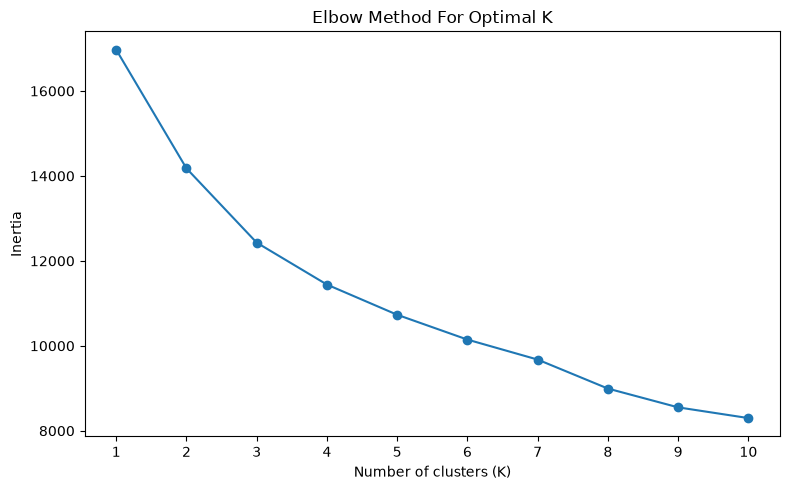

In [116]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    candidate = KMeans(n_clusters=k, random_state=42, n_init=10)
    candidate.fit(X)
    inertia.append(candidate.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K_range), inertia, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method For Optimal K")
plt.xticks(list(K_range))
plt.tight_layout()
plt.show()

In [117]:
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X)
print(df["Cluster"].value_counts().sort_index())

Cluster
0    3705
1    2678
2    3359
Name: count, dtype: int64


In [118]:
# Sampling keeps silhouette calculation practical for the full dataset.
silhouette_avg = silhouette_score(
    X, df["Cluster"], sample_size=min(2000, X.shape[0]), random_state=42
)
print(f"Silhouette Score (sample): {silhouette_avg:.2f}")

Silhouette Score (sample): 0.23


In [119]:
# SVD is only used to visualize the high-dimensional sparse feature matrix.
X_plot = TruncatedSVD(n_components=3, random_state=42).fit_transform(X)

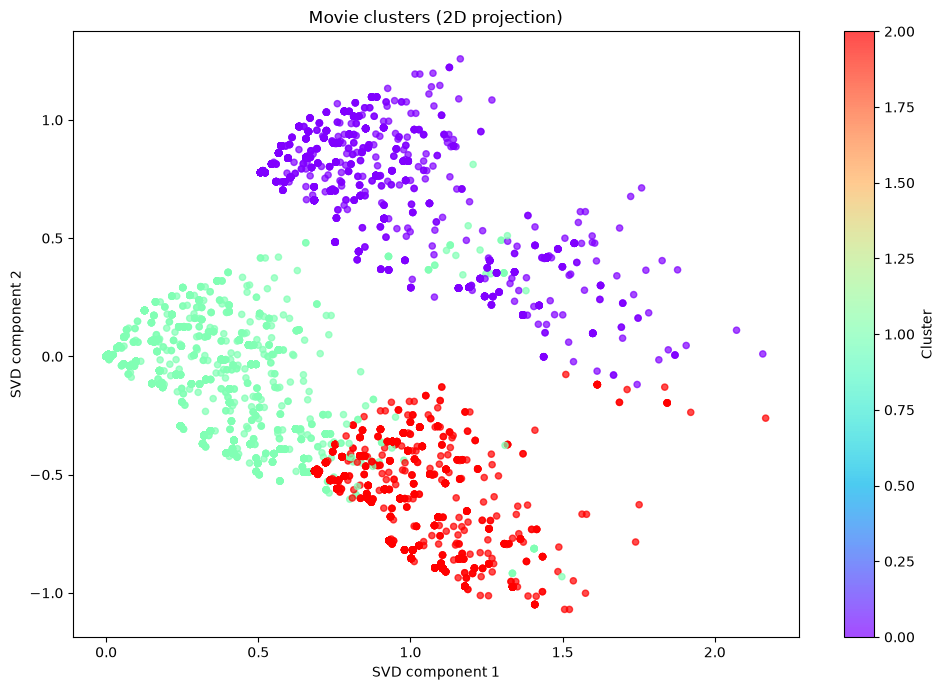

In [120]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_plot[:, 0],
    X_plot[:, 1],
    c=df["Cluster"],
    cmap="rainbow",
    s=20,
    alpha=0.7,
)
plt.xlabel("SVD component 1")
plt.ylabel("SVD component 2")
plt.title("Movie clusters (2D projection)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

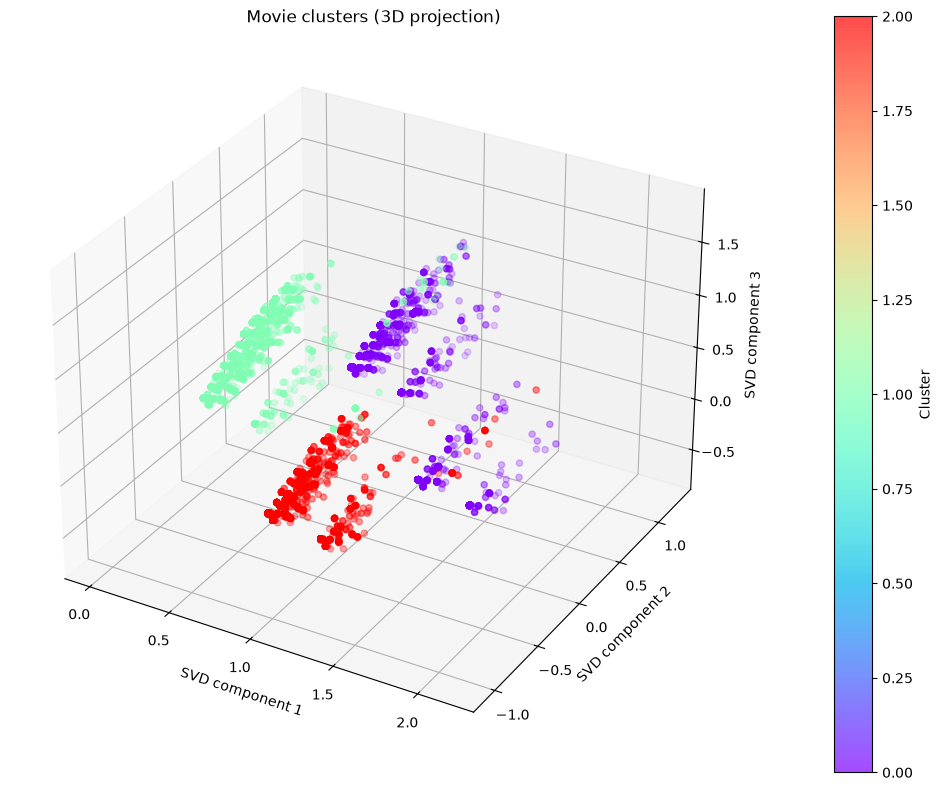

In [121]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    X_plot[:, 0],
    X_plot[:, 1],
    X_plot[:, 2],
    c=df["Cluster"],
    cmap="rainbow",
    s=20,
    alpha=0.7,
)
ax.set_xlabel("SVD component 1")
ax.set_ylabel("SVD component 2")
ax.set_zlabel("SVD component 3")
fig.colorbar(scatter, ax=ax, label="Cluster", pad=0.1)
ax.set_title("Movie clusters (3D projection)")
plt.tight_layout()
plt.show()

In [122]:
cluster_summary = df.groupby("Cluster").agg(
    movie_count=("movieId", "size"),
    common_genres=(
        "genres",
        lambda genres: genres.fillna("")
        .str.split("|", regex=False)
        .explode()
        .loc[lambda values: values.ne("")]
        .value_counts()
        .head(5)
        .index.tolist(),
    ),
    sample_titles=("title", lambda titles: titles.head(5).tolist()),
)
print(cluster_summary)

         movie_count                                  common_genres  \
Cluster                                                               
0               3705    [Comedy, Drama, Romance, Action, Adventure]   
1               2678  [Action, Thriller, Horror, Sci-Fi, Adventure]   
2               3359      [Drama, Thriller, Romance, Crime, Action]   

                                             sample_titles  
Cluster                                                     
0        [Toy Story (1995), Grumpier Old Men (1995), Wa...  
1        [Jumanji (1995), Heat (1995), Tom and Huck (19...  
2        [Nixon (1995), Casino (1995), Sense and Sensib...  


In [123]:
print("Cluster summary: movie counts, common genres, and sample titles")
print(cluster_summary)

Cluster summary: movie counts, common genres, and sample titles
         movie_count                                  common_genres  \
Cluster                                                               
0               3705    [Comedy, Drama, Romance, Action, Adventure]   
1               2678  [Action, Thriller, Horror, Sci-Fi, Adventure]   
2               3359      [Drama, Thriller, Romance, Crime, Action]   

                                             sample_titles  
Cluster                                                     
0        [Toy Story (1995), Grumpier Old Men (1995), Wa...  
1        [Jumanji (1995), Heat (1995), Tom and Huck (19...  
2        [Nixon (1995), Casino (1995), Sense and Sensib...  


In [124]:
# Save the model together with the encoder used to create its input features.
joblib.dump(kmeans, "kmeans_model.pkl")
joblib.dump(genre_binarizer, "genre_binarizer.pkl")
print("KMeans model and genre encoder saved.")

KMeans model and genre encoder saved.


In [125]:
loaded_kmeans = joblib.load("kmeans_model.pkl")
loaded_genre_binarizer = joblib.load("genre_binarizer.pkl")

new_movie = {
    "title": "New adventure movie",
    "genres": "Adventure|Animation|Children|Comedy|Fantasy",
}
new_movie_genres = new_movie["genres"].split("|")
new_movie_features = loaded_genre_binarizer.transform([new_movie_genres])
new_cluster = loaded_kmeans.predict(new_movie_features)[0]
print(f"{new_movie['title']} belongs to Cluster {new_cluster}")

New adventure movie belongs to Cluster 0


In [126]:
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as clus
from scipy.cluster.hierarchy import linkage

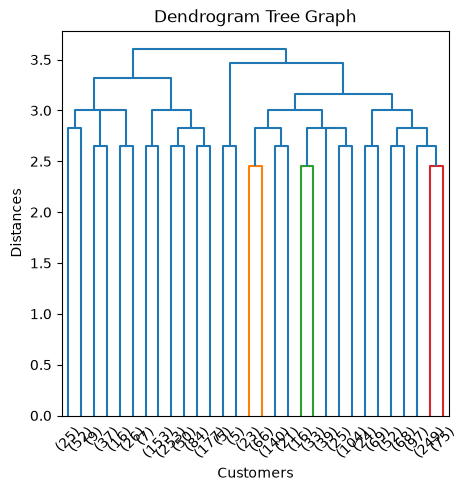

In [127]:
import numpy as np
import scipy.cluster.hierarchy as clus
from scipy.cluster.hierarchy import linkage

# Reproducible 2,000-movie sample
hierarchical_sample_indices = np.random.RandomState(42).choice(
    df.index.to_numpy(),
    size=min(2000, len(df)),
    replace=False
)

X_hierarchical = X[hierarchical_sample_indices].toarray()
hierarchical_linkage = linkage(X_hierarchical, method="complete")

plt.figure(figsize=(5, 5))
clus.dendrogram(hierarchical_linkage, truncate_mode="lastp", p=30)
plt.title('Dendrogram Tree Graph')
plt.xlabel('Customers')
plt.ylabel('Distances')
plt.show()

In [134]:
from sklearn.cluster import AgglomerativeClustering
model = AgglomerativeClustering(n_clusters = 5, linkage ='complete')
y_means = model.fit_predict(X_hierarchical)
df.loc[hierarchical_sample_indices, "Hierarchical Cluster"] = y_means
y_means

array([3, 4, 0, ..., 0, 3, 3], shape=(2000,))

In [137]:
df.shape

(9742, 5)

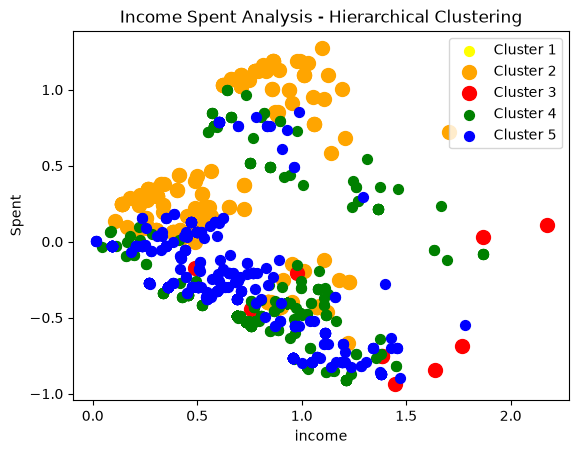

In [136]:
X = X_hierarchical_plot
# The full dataset has 9,742 movies, but y_means only labels the 2,000-movie hierarchical sample. X_hierarchical_plot contains the matching rows and the two numeric dimensions used for plotting.
plt.scatter(X[y_means==5, 0], X[y_means==5, 1], s=50, c='yellow', label ='Cluster 1')
plt.scatter(X[y_means==1, 0], X[y_means==1, 1], s=100, c='orange', label ='Cluster 2')
plt.scatter(X[y_means==2, 0], X[y_means==2, 1], s=100, c='red', label ='Cluster 3')
plt.scatter(X[y_means==3, 0], X[y_means==3, 1], s=50, c='green', label ='Cluster 4')
plt.scatter(X[y_means==4, 0], X[y_means==4, 1], s=50, c='blue', label ='Cluster 5')

# plt.scatter(X[y_means==6, 0], X[y_means==6, 1], s=50, c='black', label ='Cluster 7')

#
#plt.scatter(X[y_means==4, 0], X[y_means==4, 1], s=50, c='blue', label ='Cluster 5')
plt.title('Income Spent Analysis - Hierarchical Clustering')
plt.xlabel('income')
plt.ylabel('Spent')
plt.legend()
plt.show()

In [130]:
hierarchical_summary = (
    df.dropna(subset=["Hierarchical Cluster"])
    .groupby("Hierarchical Cluster")
    .agg(
        movie_count=("movieId", "size"),
        common_genres=(
            "genres",
            lambda genres: genres.fillna("")
            .str.split("|", regex=False)
            .explode()
            .loc[lambda values: values.ne("")]
            .value_counts()
            .head(5)
            .index.tolist(),
        ),
        sample_titles=("title", lambda titles: titles.head(5).tolist()),
    )
)
print(hierarchical_summary)

                      movie_count  \
Hierarchical Cluster                
0.0                            88   
1.0                           634   
2.0                            77   
3.0                           564   
4.0                           467   
5.0                           160   
6.0                            10   

                                                          common_genres  \
Hierarchical Cluster                                                      
0.0                       [Adventure, Action, Animation, Comedy, Drama]   
1.0                          [Drama, Crime, Romance, Thriller, Mystery]   
2.0                   [Children, Animation, Adventure, Comedy, Fantasy]   
3.0                     [Comedy, Romance, Documentary, Action, Musical]   
4.0                           [Thriller, Action, Sci-Fi, Horror, Drama]   
5.0                        [Comedy, Drama, Romance, Adventure, Fantasy]   
6.0                           [Crime, Thriller, Action, Drama, Rom

In [131]:
hierarchical_labels = y_means
hierarchical_silhouette = silhouette_score(
    X_hierarchical, hierarchical_labels
)
print(f"Hierarchical silhouette score (sample): {hierarchical_silhouette:.2f}")

Hierarchical silhouette score (sample): 0.12


In [132]:
# Save the fitted hierarchical model and the row indices used to fit it.
# AgglomerativeClustering supports fit/predict labels for fitted rows, not new rows.
hierarchical_model = model
joblib.dump(hierarchical_model, "agglomerative_model.pkl")
joblib.dump(hierarchical_sample_indices, "hierarchical_sample_indices.pkl")
print("Agglomerative model and sample row indices saved.")

Agglomerative model and sample row indices saved.
